# Ji et al. 2020 — Cutaneous SCC · 04 Correlation

Pseudotime-windowed **Gast<->pSom module correlation** across the hub, on the Gast-XOR-pSom gene set. A negative correlation running through the hub is the competitive cross-repression signature.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', 'Skin', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Skin', name)
pth_cb = os.path.join(pth_out, 'colorbars')

### Load signatures

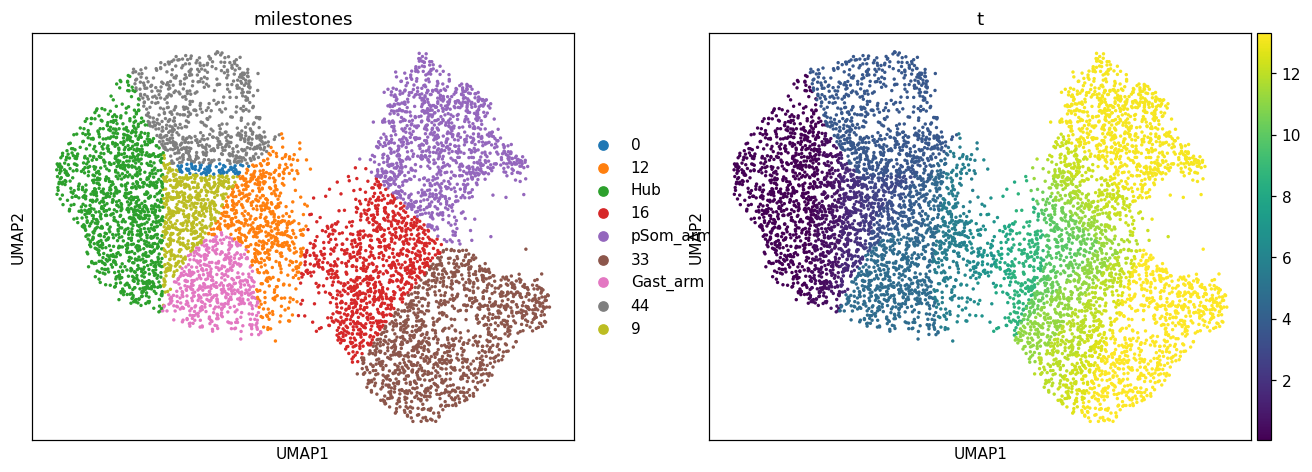

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
sc.pl.umap(adata, color = ['milestones', 't'], size = 20)

### Select module genes (Gast XOR pSom) + the hub
XOR genes are module-specific (drop shared genes). The **hub** is the `Hub` milestone — the Gast/pSom-high topological convergence at the branch point/root.

In [4]:
get_feat = lambda p: set(pd.read_csv(p).hsapiens.dropna())
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = pd.Series(list(gast ^ psom))
g = g.loc[g.isin(adata.var_names)]
print('XOR module genes present:', g.size)

XOR module genes present: 35


In [5]:
# work on raw (log1p) expression for the hub cells
msk = (adata.obs.milestones == 'Hub')
raw = adata.raw.to_adata(); raw.obs = adata.obs
adata_corr = raw[msk, g.values].copy()
adata_corr.obs['GSE162534'] = adata.obs['GSE162534'][msk].values
adata_corr.obs['GSE229103'] = adata.obs['GSE229103'][msk].values
adata_corr.obsp = adata[msk].obsp
adata_corr

AnnData object with n_obs × n_vars = 1195 × 35
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'leiden', 'GSE162534', 'GSE229103', 'rRNAModifications', 'GSE162534_sm', 'GSE229103_sm', 'rRNAModifications_sm', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'connectivities', 'distances'

### Pseudotime-windowed module correlation
Within pseudotime bins across the hub, correlate each XOR gene with the Gast score and the pSom score; the bin's module correlation is corr(gene~Gast, gene~pSom). Negative => genes that track Gast anti-track pSom (cross-repression). Smoothed over the hub kNN graph.

In [6]:
n_cells, t = 60, adata_corr.obs.t
n_bins = max(2, t.size // n_cells)
t_bin = pd.cut(t, bins = n_bins)
adata_corr.obs['t_bin'] = t_bin
grp = adata_corr.obs.groupby('t_bin', observed = True)
r_dict = {}
for b, sdf in grp:
    ab = adata_corr[sdf.index]
    X = pd.DataFrame(ab.X.toarray(), index=sdf.index, columns=g.values)
    X = X.loc[:, (X.nunique(0) > 1)]
    m1 = sdf.GSE162534.values[:, None]; m2 = sdf.GSE229103.values[:, None]
    a1 = pearsonr(X, m1, axis=0).statistic; b1 = pearsonr(X, m2, axis=0).statistic
    r_dict[b] = np.corrcoef(a1, b1)[0, 1]
A = adata_corr.obsp['connectivities']
R = t_bin.map(r_dict).astype(float)
R_sm = (A @ R) / np.asarray(A.sum(1)).ravel().clip(min=1)
adata_corr.obs['correlation'] = R_sm
print('windowed module correlation (per bin):')
print(pd.Series(r_dict).round(3).to_string())

windowed module correlation (per bin):
(0.0447, 0.084]   -0.542
(0.161, 0.2]      -0.329
(0.393, 0.431]    -0.003
(0.431, 0.47]     -0.018
(0.701, 0.74]     -0.596
(0.74, 0.778]     -0.126


### Correlation UMAP

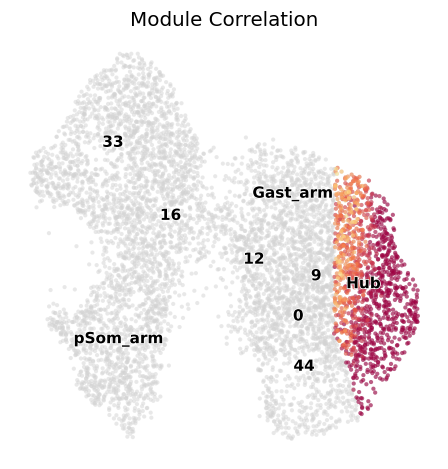

In [7]:
vlim = .5
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 30, alpha = .5, frameon = False, show = False, ax = ax)
sc.pl.umap(adata_corr, color = 'correlation', cmap = 'Spectral', vmin = -vlim, vmax = vlim,
           size = 30, alpha = .6, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'milestones', size = 30, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Module Correlation', size = 13)
fig.savefig(os.path.join(pth_out, 'correlation.pdf'), bbox_inches = 'tight')

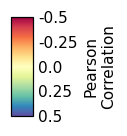

In [8]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Pearson\nCorrelation'); cb.ax.invert_yaxis()
ticks = np.asarray([-.5,-.25,0,.25,.5]); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'R_colorbar.pdf'), bbox_inches = 'tight')